### Objective

The objective of this project is to analyze historical traffic volume data from the Metro Interstate Traffic Volume dataset, identify temporal patterns and trends, and develop a model to forecast traffic volume using historical observations.

The analysis examines traffic patterns by hour, day of the week, and month, uses moving averages and lag analysis to explore changes over time, and compares Linear Regression and Random Forest models to evaluate their forecasting performance.

In [21]:

# ============================================================
# TASK 1: TIME SERIES ANALYSIS
# Metro Interstate Traffic Volume
# Setup, Google Drive, and Initial Data Inspection
# ============================================================

from pathlib import Path
import shutil
import pandas as pd
import numpy as np

from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Create a dedicated project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Time_Series_Task1"
)
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Define the dataset location in Google Drive
DATA_FILE = PROJECT_DIR / "Metro_Interstate_Traffic_Volume.csv"

# 4. Locate the uploaded CSV in Colab, if available
uploaded_files = list(
    Path("/content").glob("Metro_Interstate_Traffic_Volume.csv")
)

# Use the uploaded CSV if present; otherwise, use the Drive copy
if uploaded_files:
    SOURCE_FILE = uploaded_files[0]

    # Preserve the original dataset in Google Drive
    if SOURCE_FILE.resolve() != DATA_FILE.resolve():
        shutil.copy2(SOURCE_FILE, DATA_FILE)

elif not DATA_FILE.exists():
    raise FileNotFoundError(
        "Dataset not found in Colab or Google Drive. "
        "Upload Metro_Interstate_Traffic_Volume.csv "
        "or place it in the Time_Series_Task1 Drive folder."
    )

# 5. Load the original dataset
df = pd.read_csv(DATA_FILE)

# 6. Initial inspection
print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print(f"\nDataset location: {DATA_FILE}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nFIRST FIVE ROWS")
display(df.head())

print("\nDATA TYPES AND NON-NULL COUNTS")
df.info()

print("\nMISSING VALUES PER COLUMN")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nEXACT DUPLICATE ROWS")
print(df.duplicated().sum())

print("\nDATE COLUMN PREVIEW")
display(df["date_time"].head())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATASET LOADED SUCCESSFULLY

Dataset location: /content/drive/MyDrive/Time_Series_Task1/Metro_Interstate_Traffic_Volume.csv
Number of rows: 48,204
Number of columns: 9

COLUMN NAMES
['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main', 'weather_description', 'date_time', 'traffic_volume']

FIRST FIVE ROWS


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918



DATA TYPES AND NON-NULL COUNTS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB

MISSING VALUES PER COLUMN


,Missing Values
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0



EXACT DUPLICATE ROWS
17

DATE COLUMN PREVIEW


,date_time
0,2012-10-02 09:00:00
1,2012-10-02 10:00:00
2,2012-10-02 11:00:00
3,2012-10-02 12:00:00
4,2012-10-02 13:00:00


## 2. Data Understanding and Quality Assessment

This section examines the temporal coverage, observation frequency, timestamp integrity, missing values, and duplicate records in the dataset. Establishing these characteristics before preprocessing helps identify potential data quality issues and informs appropriate cleaning decisions. The original dataset is preserved in Google Drive so that all subsequent analysis can be performed without losing the raw data.

In [2]:

# ============================================================
# 2. DATA UNDERSTANDING AND QUALITY ASSESSMENT
# ============================================================

# Convert timestamps to datetime
df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")

# Sort chronologically for time-series analysis
df = df.sort_values("date_time").reset_index(drop=True)

# Basic temporal coverage
print("=" * 65)
print("1. TEMPORAL COVERAGE")
print("=" * 65)
print(f"First timestamp: {df['date_time'].min()}")
print(f"Last timestamp:  {df['date_time'].max()}")
print(f"Total observations: {len(df):,}")
print(f"Unique timestamps: {df['date_time'].nunique():,}")

# Timestamp intervals
print("\n" + "=" * 65)
print("2. OBSERVATION FREQUENCY")
print("=" * 65)

time_differences = df["date_time"].diff().dropna()
print("\nMost common timestamp intervals:")
display(
    time_differences.value_counts().head(10).rename_axis(
        "Time Interval"
    ).to_frame("Count")
)

print(f"\nExactly one-hour intervals: {(time_differences == pd.Timedelta(hours=1)).sum():,}")
print(f"Intervals longer than one hour: {(time_differences > pd.Timedelta(hours=1)).sum():,}")
print(f"Intervals shorter than one hour: {(time_differences < pd.Timedelta(hours=1)).sum():,}")

# Duplicate timestamps
print("\n" + "=" * 65)
print("3. TIMESTAMP INTEGRITY")
print("=" * 65)
print(f"Duplicate timestamps: {df['date_time'].duplicated().sum():,}")
print(f"Invalid timestamps: {df['date_time'].isna().sum():,}")

# Missing values
print("\n" + "=" * 65)
print("4. MISSING VALUES")
print("=" * 65)

missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

# Exact duplicate rows
print("\n" + "=" * 65)
print("5. EXACT DUPLICATE ROWS")
print("=" * 65)
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

# Numeric summary
print("\n" + "=" * 65)
print("6. NUMERICAL SUMMARY")
print("=" * 65)
display(df.describe().round(2))

print("\nAssessment complete. No rows have been deleted.")


1. TEMPORAL COVERAGE
First timestamp: 2012-10-02 09:00:00
Last timestamp:  2018-09-30 23:00:00
Total observations: 48,204
Unique timestamps: 40,575

2. OBSERVATION FREQUENCY

Most common timestamp intervals:


,Count
Time Interval,
0 days 01:00:00,37986
0 days 00:00:00,7629
0 days 02:00:00,2192
0 days 03:00:00,201
0 days 04:00:00,59
0 days 05:00:00,33
0 days 06:00:00,17
0 days 08:00:00,13
0 days 10:00:00,13



Exactly one-hour intervals: 37,986
Intervals longer than one hour: 2,588
Intervals shorter than one hour: 7,629

3. TIMESTAMP INTEGRITY
Duplicate timestamps: 7,629
Invalid timestamps: 0

4. MISSING VALUES


,Missing Count,Missing Percentage (%)
holiday,48143,99.87
temp,0,0.00
rain_1h,0,0.00
snow_1h,0,0.00
clouds_all,0,0.00
weather_main,0,0.00
weather_description,0,0.00
date_time,0,0.00
traffic_volume,0,0.00



5. EXACT DUPLICATE ROWS
Exact duplicate rows: 17

6. NUMERICAL SUMMARY


,temp,rain_1h,snow_1h,clouds_all,date_time,traffic_volume
count,48204.00,48204.00,48204.00,48204.00,48204,48204.00
mean,281.21,0.33,0.00,49.36,2016-01-05 10:46:16.773711616,3259.82
min,0.00,0.00,0.00,0.00,2012-10-02 09:00:00,0.00
25%,272.16,0.00,0.00,1.00,2014-02-06 11:45:00,1193.00
50%,282.45,0.00,0.00,64.00,2016-06-11 03:30:00,3380.00
75%,291.81,0.00,0.00,90.00,2017-08-11 06:00:00,4933.00
max,310.07,9831.30,0.51,100.00,2018-09-30 23:00:00,7280.00
std,13.34,44.79,0.01,39.02,NaN,1986.86



Assessment complete. No rows have been deleted.


## 3. Investigation of Duplicate Timestamps and Potential Anomalies

The initial data quality assessment revealed repeated timestamps, 17 exact duplicate rows, and an unusually high maximum value in the `rain_1h` column. These issues require further investigation before preprocessing.

Repeated timestamps do not necessarily represent identical observations. Records sharing a timestamp may contain different traffic measurements or weather conditions. Therefore, the analysis will examine timestamp group sizes and compare the values recorded within repeated timestamps.

Potentially anomalous rainfall measurements will also be inspected to determine whether they require further verification. No records will be removed or modified during this investigation.

In [3]:

# ============================================================
# 3. INVESTIGATE DUPLICATES AND POTENTIAL ANOMALIES
# ============================================================

# A. How many records share each timestamp?
timestamp_counts = df.groupby("date_time").size()

repeated_timestamps = timestamp_counts[timestamp_counts > 1]

print("=" * 60)
print("A. REPEATED TIMESTAMPS")
print("=" * 60)
print(f"Unique timestamps appearing more than once: {len(repeated_timestamps):,}")
print(f"Rows belonging to repeated timestamps: {repeated_timestamps.sum():,}")
print(f"Maximum records at one timestamp: {timestamp_counts.max()}")
print("\nDistribution of records per timestamp:")
display(timestamp_counts.value_counts().sort_index().rename_axis(
    "Records per Timestamp"
).to_frame("Number of Timestamps"))

# B. Inspect examples of repeated timestamps
print("\n" + "=" * 60)
print("B. EXAMPLES OF REPEATED TIMESTAMPS")
print("=" * 60)

duplicate_examples = df[
    df["date_time"].isin(repeated_timestamps.index)
].sort_values("date_time")

display(
    duplicate_examples[
        ["date_time", "traffic_volume", "temp", "rain_1h",
         "snow_1h", "clouds_all", "weather_main", "holiday"]
    ].head(12)
)

# C. Do repeated timestamps have different traffic values?
traffic_variation = df.groupby("date_time")["traffic_volume"].nunique()

conflicting_traffic_timestamps = traffic_variation[traffic_variation > 1]

print("\n" + "=" * 60)
print("C. TRAFFIC VALUE CONSISTENCY")
print("=" * 60)
print(
    "Repeated timestamps with different traffic volumes:",
    len(conflicting_traffic_timestamps)
)
print(
    "Repeated timestamps with identical traffic volumes:",
    (traffic_variation[repeated_timestamps.index] == 1).sum()
)

# D. Inspect the largest rainfall values
print("\n" + "=" * 60)
print("D. LARGEST RAINFALL VALUES")
print("=" * 60)

display(
    df.nlargest(10, "rain_1h")[
        ["date_time", "rain_1h", "traffic_volume",
         "temp", "weather_main", "weather_description"]
    ]
)

print("\nInvestigation complete. The dataset remains unchanged.")


A. REPEATED TIMESTAMPS
Unique timestamps appearing more than once: 5,445
Rows belonging to repeated timestamps: 13,074
Maximum records at one timestamp: 6

Distribution of records per timestamp:


,Number of Timestamps
Records per Timestamp,
1,35130
2,3617
3,1513
4,276
5,37
6,2



B. EXAMPLES OF REPEATED TIMESTAMPS


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,holiday
178,2012-10-10 07:00:00,6793,281.25,0.0,0.0,99,Rain,NaN
179,2012-10-10 07:00:00,6793,281.25,0.0,0.0,99,Drizzle,NaN
180,2012-10-10 08:00:00,6283,280.10,0.0,0.0,99,Rain,NaN
181,2012-10-10 08:00:00,6283,280.10,0.0,0.0,99,Drizzle,NaN
182,2012-10-10 09:00:00,5680,279.61,0.0,0.0,99,Rain,NaN
183,2012-10-10 09:00:00,5680,279.61,0.0,0.0,99,Drizzle,NaN
269,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Drizzle,NaN
270,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Mist,NaN
271,2012-10-14 09:00:00,2685,282.43,0.0,0.0,57,Haze,NaN
272,2012-10-14 10:00:00,3370,282.33,0.0,0.0,57,Drizzle,NaN



C. TRAFFIC VALUE CONSISTENCY
Repeated timestamps with different traffic volumes: 0
Repeated timestamps with identical traffic volumes: 5445

D. LARGEST RAINFALL VALUES


,date_time,rain_1h,traffic_volume,temp,weather_main,weather_description
24872,2016-07-11 17:00:00,9831.30,5535,302.11,Rain,very heavy rain
8247,2013-08-07 02:00:00,55.63,315,289.10,Rain,very heavy rain
7179,2013-06-24 11:00:00,44.45,4802,295.82,Rain,very heavy rain
25779,2016-08-16 17:00:00,31.75,4913,297.71,Rain,very heavy rain
10806,2013-12-19 23:00:00,28.70,1190,264.50,Rain,very heavy rain
10807,2013-12-19 23:00:00,28.70,1190,264.50,Snow,light snow
16504,2015-07-13 00:00:00,27.57,492,292.02,Rain,very heavy rain
16505,2015-07-13 00:00:00,27.57,492,292.02,Thunderstorm,proximity thunderstorm
16506,2015-07-13 00:00:00,27.57,492,292.02,Mist,mist
17437,2015-08-16 21:00:00,25.46,2118,294.49,Mist,mist



Investigation complete. The dataset remains unchanged.


## 4. Detailed Assessment of Repeated Observations and Rainfall

This section investigates whether repeated timestamps contain conflicting numerical measurements or primarily reflect differences in weather labels. It also examines the distribution of hourly rainfall to identify potentially erroneous or extreme observations. The results will inform the choice of preprocessing methods while preserving the original dataset.

In [4]:

# ============================================================
# 4. DETAILED DUPLICATE AND RAINFALL INVESTIGATION
# ============================================================

# A. Check whether numerical measurements agree per timestamp
numeric_cols = [
    "traffic_volume", "temp", "rain_1h",
    "snow_1h", "clouds_all"
]

numeric_variation = df.groupby("date_time")[numeric_cols].nunique()
conflicting_numeric = numeric_variation.gt(1).any(axis=1)

print("=" * 60)
print("A. NUMERICAL CONSISTENCY WITHIN TIMESTAMPS")
print("=" * 60)
print(
    "Timestamps with conflicting numerical measurements:",
    conflicting_numeric.sum()
)

# B. Check variation in weather labels
weather_variation = df.groupby("date_time")[
    ["weather_main", "weather_description"]
].nunique()

print("\n" + "=" * 60)
print("B. WEATHER LABEL VARIATION")
print("=" * 60)
print(
    "Timestamps with multiple weather_main labels:",
    weather_variation["weather_main"].gt(1).sum()
)
print(
    "Timestamps with multiple weather descriptions:",
    weather_variation["weather_description"].gt(1).sum()
)

# C. Rainfall distribution and extreme values
print("\n" + "=" * 60)
print("C. RAINFALL DISTRIBUTION")
print("=" * 60)

display(df["rain_1h"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
).to_frame("rain_1h").round(3))

for threshold in [10, 25, 50, 100, 1000]:
    count = (df["rain_1h"] > threshold).sum()
    print(f"Values above {threshold:>4} mm: {count:,}")

print("\nLargest rainfall values:")
display(
    df.loc[df["rain_1h"] > 10, [
        "date_time", "rain_1h", "traffic_volume",
        "weather_main", "weather_description"
    ]].sort_values("rain_1h", ascending=False).head(10)
)

print("\nDiagnostic complete. No data has been changed.")


A. NUMERICAL CONSISTENCY WITHIN TIMESTAMPS
Timestamps with conflicting numerical measurements: 79

B. WEATHER LABEL VARIATION
Timestamps with multiple weather_main labels: 5349
Timestamps with multiple weather descriptions: 5386

C. RAINFALL DISTRIBUTION


,rain_1h
count,48204.000
mean,0.334
std,44.789
min,0.000
50%,0.000
90%,0.000
95%,0.300
99%,3.270
99.9%,13.603
max,9831.300


Values above   10 mm: 94
Values above   25 mm: 15
Values above   50 mm: 2
Values above  100 mm: 1
Values above 1000 mm: 1

Largest rainfall values:


,date_time,rain_1h,traffic_volume,weather_main,weather_description
24872,2016-07-11 17:00:00,9831.30,5535,Rain,very heavy rain
8247,2013-08-07 02:00:00,55.63,315,Rain,very heavy rain
7179,2013-06-24 11:00:00,44.45,4802,Rain,very heavy rain
25779,2016-08-16 17:00:00,31.75,4913,Rain,very heavy rain
10807,2013-12-19 23:00:00,28.70,1190,Snow,light snow
10806,2013-12-19 23:00:00,28.70,1190,Rain,very heavy rain
16505,2015-07-13 00:00:00,27.57,492,Thunderstorm,proximity thunderstorm
16504,2015-07-13 00:00:00,27.57,492,Rain,very heavy rain
16506,2015-07-13 00:00:00,27.57,492,Mist,mist
17437,2015-08-16 21:00:00,25.46,2118,Mist,mist



Diagnostic complete. No data has been changed.


In [5]:

# ============================================================
# 5. IDENTIFY CONFLICTING NUMERICAL RECORDS
# ============================================================

numeric_cols = [
    "traffic_volume", "temp", "rain_1h",
    "snow_1h", "clouds_all"
]

# Count timestamps where each numerical column has conflicting values
variation = df.groupby("date_time")[numeric_cols].nunique()

conflict_counts = variation.gt(1).sum().rename(
    "Timestamps with Conflicting Values"
)

print("CONFLICTS BY NUMERICAL COLUMN")
display(conflict_counts.to_frame())

# Inspect records at timestamps with numerical conflicts
conflict_timestamps = variation.index[variation.gt(1).any(axis=1)]

conflict_records = df[
    df["date_time"].isin(conflict_timestamps)
].sort_values("date_time")

print(f"\nTotal conflicting timestamps: {len(conflict_timestamps)}")
print(f"Total rows involved: {len(conflict_records)}")

print("\nFIRST 20 RECORDS AT CONFLICTING TIMESTAMPS")
display(conflict_records[
    ["date_time", "traffic_volume", "temp", "rain_1h",
     "snow_1h", "clouds_all", "weather_main",
     "weather_description"]
].head(20))

print("\nNo data has been modified.")


CONFLICTS BY NUMERICAL COLUMN


,Timestamps with Conflicting Values
traffic_volume,0
temp,78
rain_1h,9
snow_1h,0
clouds_all,32



Total conflicting timestamps: 79
Total rows involved: 186

FIRST 20 RECORDS AT CONFLICTING TIMESTAMPS


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
878,2012-11-04 01:00:00,730,275.600,0.0,0.0,90,Clouds,overcast clouds
879,2012-11-04 01:00:00,730,275.770,0.0,0.0,90,Clouds,overcast clouds
11202,2014-01-03 20:00:00,2427,267.970,0.0,0.0,90,Clouds,overcast clouds
11203,2014-01-03 20:00:00,2427,268.880,0.0,0.0,90,Clouds,overcast clouds
11337,2014-01-09 16:00:00,6421,265.730,0.0,0.0,40,Clouds,scattered clouds
11338,2014-01-09 16:00:00,6421,266.470,0.0,0.0,64,Clouds,broken clouds
11387,2014-01-11 16:00:00,4546,271.040,0.0,0.0,20,Clouds,few clouds
11388,2014-01-11 16:00:00,4546,272.020,0.0,0.0,64,Clouds,broken clouds
11481,2014-01-15 00:00:00,515,258.500,0.0,0.0,20,Clouds,few clouds
11482,2014-01-15 00:00:00,515,259.140,0.0,0.0,64,Clouds,broken clouds



No data has been modified.


### 3. Investigating Duplicate Records and Anomalies

Repeated timestamps were found in the dataset, with some records containing inconsistent weather measurements. Traffic volume remains consistent across repeated timestamps, so these duplicates can be consolidated without changing the forecasting target for timestamps with repeated records. Numerical weather measurements will be aggregated when timestamps are consolidated, while categorical weather descriptions will be handled separately.

An extreme rainfall value was also identified and will be investigated before deciding how to treat it. The original dataset will remain unchanged.

In [6]:
# Examine the size of disagreements at repeated timestamps
numeric_cols = ["temp", "rain_1h", "snow_1h", "clouds_all"]

variation = df.groupby("date_time")[numeric_cols].agg(
    lambda values: values.max() - values.min()
)

print("Largest differences between records sharing a timestamp:")
display(variation.max().rename("Maximum Difference").to_frame())

print("\nConflicting timestamps with the largest temperature differences:")
temp_conflicts = variation[variation["temp"] > 0].sort_values(
    "temp", ascending=False
)
display(temp_conflicts.head(10))

print("\nRecords containing the extreme rainfall value:")
display(
    df.loc[
        df["rain_1h"] > 100,
        [
            "date_time", "traffic_volume", "temp", "rain_1h",
            "snow_1h", "clouds_all", "weather_main",
            "weather_description"
        ]
    ]
)

print("\nOriginal dataset remains unchanged.")

Largest differences between records sharing a timestamp:


,Maximum Difference
temp,20.433
rain_1h,0.760
snow_1h,0.000
clouds_all,75.000



Conflicting timestamps with the largest temperature differences:


,temp,rain_1h,snow_1h,clouds_all
date_time,,,,
2014-01-17 06:00:00,20.433,0.0,0.0,24
2014-01-17 03:00:00,17.833,0.0,0.0,26
2014-01-17 12:00:00,16.613,0.0,0.0,63
2014-01-17 16:00:00,15.793,0.0,0.0,44
2016-10-08 17:00:00,3.547,0.0,0.0,20
2016-10-15 11:00:00,2.814,0.0,0.0,0
2014-01-20 16:00:00,1.140,0.0,0.0,11
2014-01-11 16:00:00,0.980,0.0,0.0,44
2014-01-03 20:00:00,0.910,0.0,0.0,0



Records containing the extreme rainfall value:


,date_time,traffic_volume,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description
24872,2016-07-11 17:00:00,5535,302.11,9831.3,0.0,75,Rain,very heavy rain



Original dataset remains unchanged.


In [7]:
print("Holiday values:")
display(df["holiday"].value_counts(dropna=False).head(10))

print("\nRecord with extreme rainfall:")
display(df.loc[df["rain_1h"] == df["rain_1h"].max()])

print("\nNumber of unique timestamps:", df["date_time"].nunique())
print("Number of rows:", len(df))

Holiday values:


,count
holiday,
NaN,48143
Labor Day,7
Christmas Day,6
Thanksgiving Day,6
Martin Luther King Jr Day,6
New Years Day,6
Veterans Day,5
Columbus Day,5
Memorial Day,5



Record with extreme rainfall:


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
24872,NaN,302.11,9831.3,0.0,75,Rain,very heavy rain,2016-07-11 17:00:00,5535



Number of unique timestamps: 40575
Number of rows: 48204


In [8]:
# Create a separate working copy
clean_df = df.copy()

# Treat missing holiday labels as non-holiday records
clean_df["holiday"] = clean_df["holiday"].fillna("None")

# Treat the extreme rainfall measurement as invalid
clean_df.loc[clean_df["rain_1h"] == 9831.3, "rain_1h"] = np.nan

# Consolidate repeated timestamps:
# average numerical measurements and retain the first observed holiday/weather labels
numeric_cols = [
    "temp", "rain_1h", "snow_1h", "clouds_all", "traffic_volume"
]
categorical_cols = [
    "holiday", "weather_main", "weather_description"
]

clean_df = clean_df.groupby("date_time", as_index=False).agg(
    {
        **{col: "mean" for col in numeric_cols},
        **{col: "first" for col in categorical_cols},
    }
)

# Restore chronological order
clean_df = clean_df.sort_values("date_time").reset_index(drop=True)

print("Original rows:", len(df))
print("Rows after consolidating timestamps:", len(clean_df))
print("Remaining duplicate timestamps:", clean_df["date_time"].duplicated().sum())
print("Missing values after cleaning:")
display(clean_df.isna().sum().to_frame("Missing Values"))

Original rows: 48204
Rows after consolidating timestamps: 40575
Remaining duplicate timestamps: 0
Missing values after cleaning:


,Missing Values
date_time,0
temp,0
rain_1h,1
snow_1h,0
clouds_all,0
traffic_volume,0
holiday,0
weather_main,0
weather_description,0


In [9]:
# Replace the single invalid rainfall value with the median rainfall
clean_df["rain_1h"] = clean_df["rain_1h"].fillna(
    clean_df["rain_1h"].median()
)

# Verify the cleaned dataset
print("Dataset shape:", clean_df.shape)
print("Missing values:", clean_df.isna().sum().sum())
print("Duplicate timestamps:", clean_df["date_time"].duplicated().sum())
print("Time range:", clean_df["date_time"].min(), "to", clean_df["date_time"].max())

Dataset shape: (40575, 9)
Missing values: 0
Duplicate timestamps: 0
Time range: 2012-10-02 09:00:00 to 2018-09-30 23:00:00


## 4. Exploratory Data Analysis

### 4.1 Traffic Volume Over Time

This section examines how traffic volume changes over the dataset's time range. Visualizing traffic volume over time helps reveal overall patterns, fluctuations, and possible trends before building forecasting models.

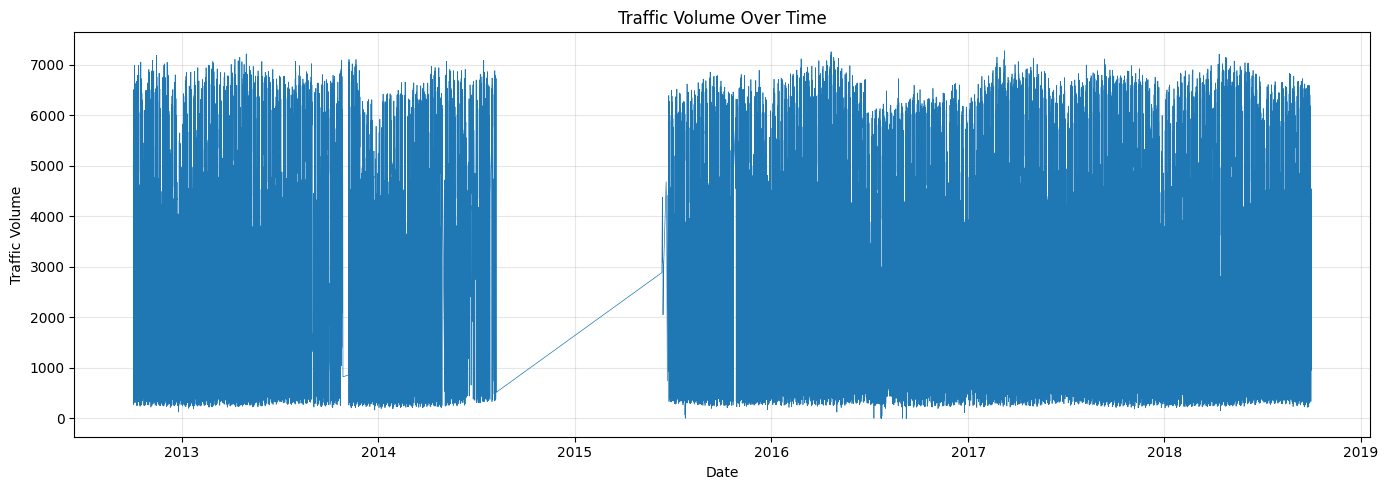

Plot saved to: /content/drive/MyDrive/Time_Series_Task1/traffic_volume_over_time.png


In [11]:
# Plot and automatically save to Google Drive
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(clean_df["date_time"], clean_df["traffic_volume"], linewidth=0.5)
plt.title("Traffic Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save the figure to your project folder in Google Drive
plot_path = Path("/content/drive/MyDrive/Time_Series_Task1/traffic_volume_over_time.png")
plt.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()
print(f"Plot saved to: {plot_path}")

### 4.2 Question 1: How Does Traffic Volume Vary by Hour of the Day?

This analysis examines the average traffic volume for each hour of the day to identify peak and off-peak traffic periods.

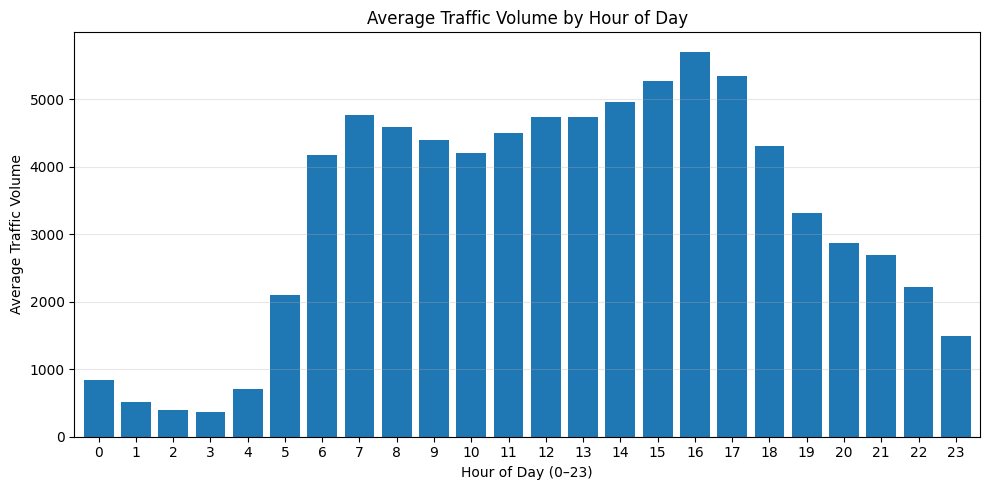

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question1_traffic_by_hour.png
Peak traffic hour: 16:00
Lowest traffic hour: 03:00


In [12]:
# Question 1: Average traffic volume by hour of day
import matplotlib.pyplot as plt

clean_df["hour"] = clean_df["date_time"].dt.hour
hourly_traffic = clean_df.groupby("hour")["traffic_volume"].mean()

plt.figure(figsize=(10, 5))
hourly_traffic.plot(kind="bar", width=0.8)
plt.title("Average Traffic Volume by Hour of Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question1_traffic_by_hour.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
print(f"Peak traffic hour: {hourly_traffic.idxmax():02d}:00")
print(f"Lowest traffic hour: {hourly_traffic.idxmin():02d}:00")

### 4.3 Question 2: Does Traffic Volume Differ Between Weekdays and Weekends?

This analysis compares average traffic volume on weekdays and weekends to determine whether traffic patterns differ between working days and non-working days.

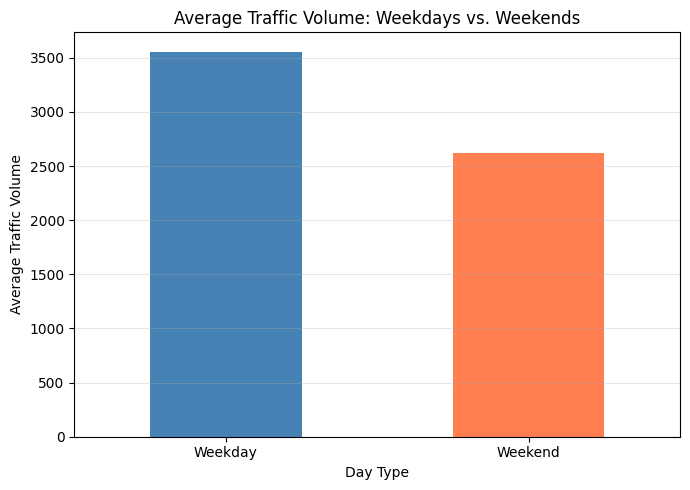

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question2_weekday_vs_weekend.png


,Average Traffic Volume
day_type,
Weekday,3557.440457
Weekend,2623.928596


In [13]:
# Question 2: Weekday vs. weekend traffic
clean_df["day_of_week"] = clean_df["date_time"].dt.dayofweek
clean_df["day_type"] = clean_df["day_of_week"].map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

day_type_traffic = clean_df.groupby("day_type")["traffic_volume"].mean()
day_type_traffic = day_type_traffic.reindex(["Weekday", "Weekend"])

plt.figure(figsize=(7, 5))
day_type_traffic.plot(kind="bar", color=["steelblue", "coral"])
plt.title("Average Traffic Volume: Weekdays vs. Weekends")
plt.xlabel("Day Type")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question2_weekday_vs_weekend.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
display(day_type_traffic.rename("Average Traffic Volume").to_frame())

### 4.4 Question 3: How Does Average Traffic Volume Vary by Day of the Week?

This analysis compares average traffic volume across the seven days of the week to identify which days experience higher or lower traffic.

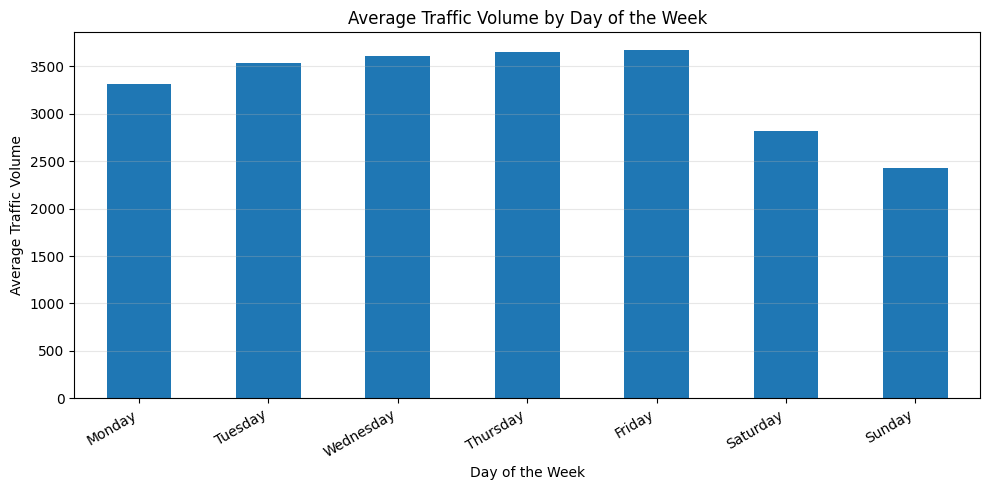

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question3_traffic_by_day.png
Highest-traffic day: Friday (3674.78)
Lowest-traffic day: Sunday (2426.25)


In [14]:
# Question 3: Average traffic by day of week
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

clean_df["day_name"] = clean_df["date_time"].dt.day_name()
daily_traffic = clean_df.groupby("day_name")["traffic_volume"].mean()
daily_traffic = daily_traffic.reindex(day_names)

plt.figure(figsize=(10, 5))
daily_traffic.plot(kind="bar")
plt.title("Average Traffic Volume by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question3_traffic_by_day.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
print("Highest-traffic day:", daily_traffic.idxmax(),
      f"({daily_traffic.max():.2f})")
print("Lowest-traffic day:", daily_traffic.idxmin(),
      f"({daily_traffic.min():.2f})")

### 4.5 Question 4: How Does Traffic Volume Vary by Month?

This analysis compares average traffic volume across the months of the year to identify seasonal patterns in traffic.

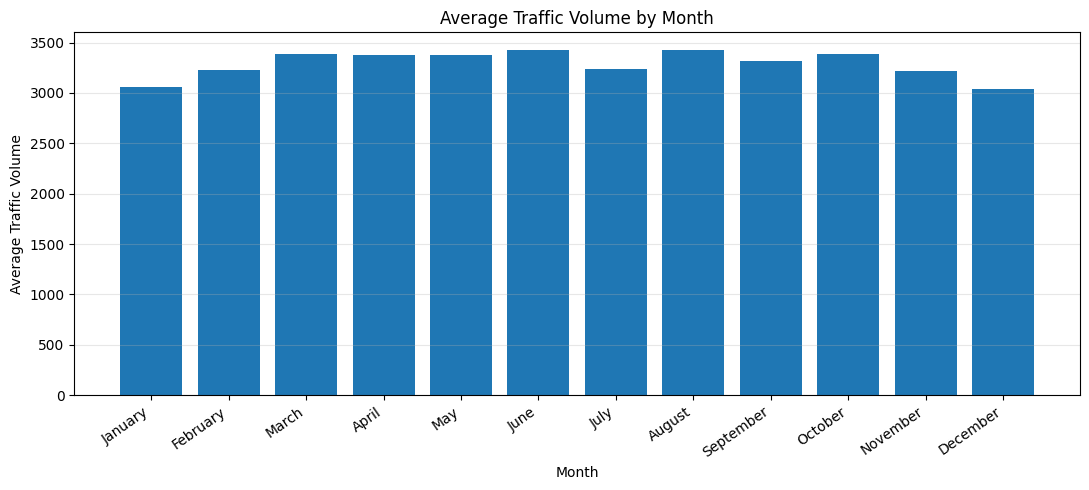

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question4_traffic_by_month.png
Highest-traffic month: August (3430.32)
Lowest-traffic month: December (3040.19)


In [15]:
# Question 4: Average traffic by month
month_names = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

clean_df["month"] = clean_df["date_time"].dt.month
monthly_traffic = clean_df.groupby("month")["traffic_volume"].mean()
monthly_traffic = monthly_traffic.reindex(range(1, 13))

plt.figure(figsize=(11, 5))
plt.bar(month_names, monthly_traffic.values)
plt.title("Average Traffic Volume by Month")
plt.xlabel("Month")
plt.ylabel("Average Traffic Volume")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question4_traffic_by_month.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
print("Highest-traffic month:", month_names[monthly_traffic.idxmax() - 1],
      f"({monthly_traffic.max():.2f})")
print("Lowest-traffic month:", month_names[monthly_traffic.idxmin() - 1],
      f"({monthly_traffic.min():.2f})")

### 4.6 Question 5: How Does a 24-Hour Moving Average Reveal Traffic Trends?

Hourly traffic fluctuates considerably. A 24-observation rolling average smooths short-term fluctuations and helps reveal broader changes in traffic volume. Because some timestamps are missing, this represents 24 observations rather than guaranteed 24 consecutive hours.

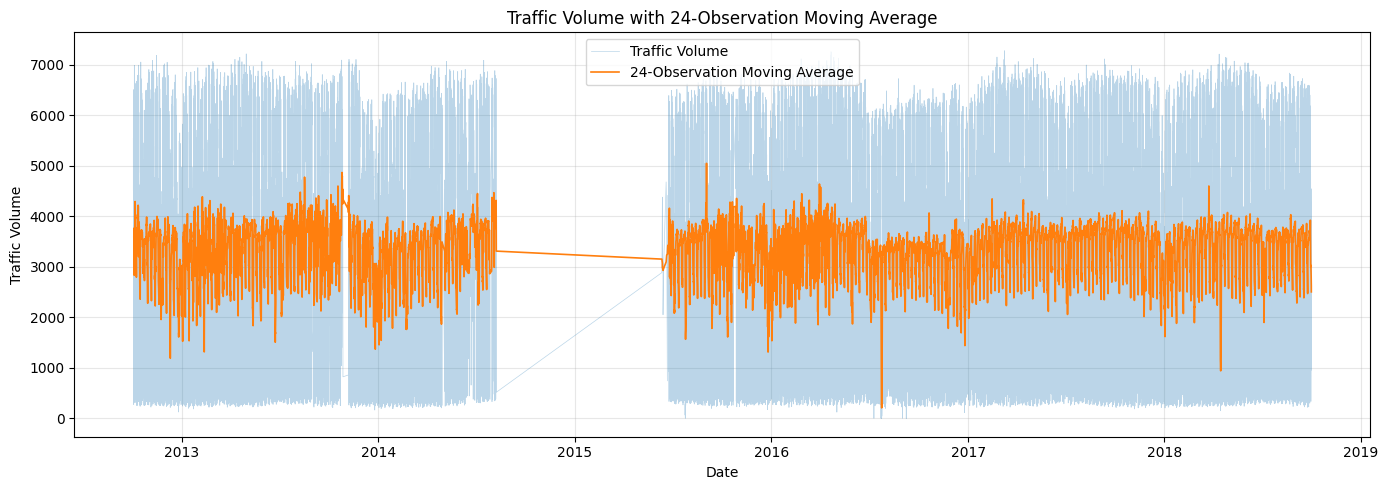

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question5_moving_average.png
Moving average calculated for 40,552 observations.


In [16]:
# Question 5: Traffic volume and 24-observation moving average
clean_df["traffic_ma_24"] = clean_df["traffic_volume"].rolling(
    window=24, min_periods=24
).mean()

plt.figure(figsize=(14, 5))
plt.plot(
    clean_df["date_time"], clean_df["traffic_volume"],
    alpha=0.3, linewidth=0.5, label="Traffic Volume"
)
plt.plot(
    clean_df["date_time"], clean_df["traffic_ma_24"],
    linewidth=1.2, label="24-Observation Moving Average"
)
plt.title("Traffic Volume with 24-Observation Moving Average")
plt.xlabel("Date")
plt.ylabel("Traffic Volume")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question5_moving_average.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
print(f"Moving average calculated for {(clean_df['traffic_ma_24'].notna()).sum():,} observations.")

### 4.7 Question 6: How Strongly Is Traffic Volume Related to the Previous Observation?

Lag analysis compares current traffic volume with traffic volume from the previous observation. A strong relationship would indicate that recent traffic levels may be useful for forecasting. Since the dataset contains gaps in its timestamps, the lag represents the previous available observation, which may not always be exactly one hour earlier.

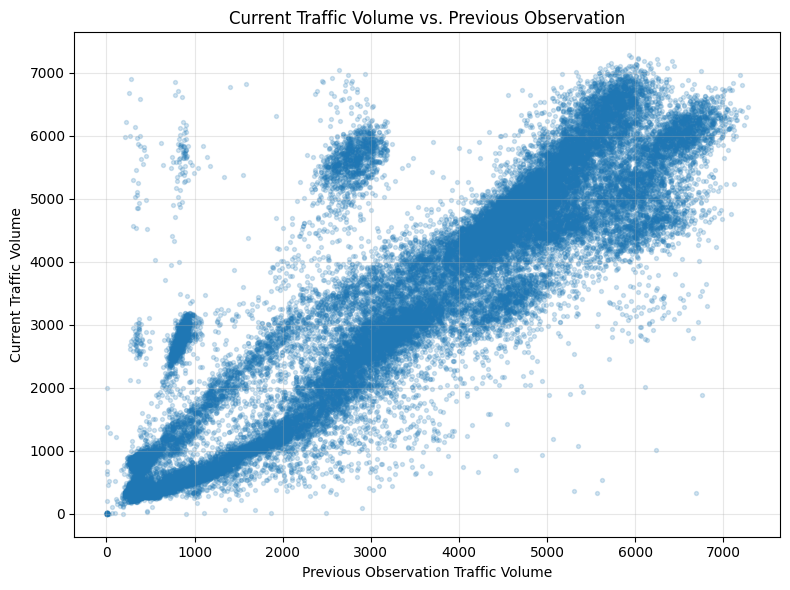

Chart saved to: /content/drive/MyDrive/Time_Series_Task1/question6_lag_analysis.png
Correlation with previous observation: 0.8961


In [17]:
# Question 6: Lag-1 traffic analysis
clean_df["traffic_lag_1"] = clean_df["traffic_volume"].shift(1)

lag_corr = clean_df["traffic_volume"].corr(clean_df["traffic_lag_1"])

plt.figure(figsize=(8, 6))
plt.scatter(
    clean_df["traffic_lag_1"],
    clean_df["traffic_volume"],
    alpha=0.2,
    s=8
)
plt.title("Current Traffic Volume vs. Previous Observation")
plt.xlabel("Previous Observation Traffic Volume")
plt.ylabel("Current Traffic Volume")
plt.grid(alpha=0.3)
plt.tight_layout()

plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/question6_lag_analysis.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved to: {plot_path}")
print(f"Correlation with previous observation: {lag_corr:.4f}")

## 5. Time-Series Forecasting

The exploratory analysis identified daily and weekly traffic patterns, as well as a strong relationship between consecutive observations. This section prepares the data for forecasting and compares two model experiments using chronological training, validation, and test sets.

In [18]:
# Prepare forecasting features and chronological splits
model_df = clean_df[["date_time", "traffic_volume"]].copy()

model_df["hour"] = model_df["date_time"].dt.hour
model_df["day_of_week"] = model_df["date_time"].dt.dayofweek
model_df["month"] = model_df["date_time"].dt.month
model_df["traffic_lag_1"] = model_df["traffic_volume"].shift(1)
model_df["traffic_lag_24"] = model_df["traffic_volume"].shift(24)
model_df["traffic_ma_24"] = (
    model_df["traffic_volume"].shift(1).rolling(24).mean()
)

# Remove rows without enough historical observations
model_df = model_df.dropna().reset_index(drop=True)

# Chronological split: 70% train, 15% validation, 15% test
n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

# Save prepared data and splits to Drive
output_dir = Path("/content/drive/MyDrive/Time_Series_Task1")
model_df.to_csv(output_dir / "prepared_forecasting_data.csv", index=False)
train_df.to_csv(output_dir / "train_data.csv", index=False)
val_df.to_csv(output_dir / "validation_data.csv", index=False)
test_df.to_csv(output_dir / "test_data.csv", index=False)

print("Prepared dataset:", model_df.shape)
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))
print("Training period:", train_df["date_time"].min(), "to", train_df["date_time"].max())
print("Validation period:", val_df["date_time"].min(), "to", val_df["date_time"].max())
print("Test period:", test_df["date_time"].min(), "to", test_df["date_time"].max())
print(f"Prepared datasets saved to: {output_dir}")

Prepared dataset: (40551, 8)
Training rows: 28385
Validation rows: 6083
Test rows: 6083
Training period: 2012-10-03 12:00:00 to 2017-05-10 11:00:00
Validation period: 2017-05-10 12:00:00 to 2018-01-19 18:00:00
Test period: 2018-01-19 19:00:00 to 2018-09-30 23:00:00
Prepared datasets saved to: /content/drive/MyDrive/Time_Series_Task1


### 5.1 Model Experiments and Evaluation

Two regression models will be compared using the same time-based features and chronological data splits. Linear Regression provides a baseline, while Random Forest can capture nonlinear relationships. Validation performance will guide model selection, and the test set will be reserved for final evaluation.

Models will be evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and coefficient of determination (R²).

In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Define features and target
feature_cols = [
    "hour", "day_of_week", "month",
    "traffic_lag_1", "traffic_lag_24", "traffic_ma_24"
]
target_col = "traffic_volume"

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

# Experiment 1: Linear Regression baseline
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_val_pred = linear_model.predict(X_val)

# Experiment 2: Tune Random Forest using validation performance
rf_results = []

for n_estimators in [100, 200]:
    for max_depth in [10, 20]:
        rf_model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
        rf_model.fit(X_train, y_train)
        val_pred = rf_model.predict(X_val)

        rf_results.append({
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "MAE": mean_absolute_error(y_val, val_pred),
            "RMSE": np.sqrt(mean_squared_error(y_val, val_pred)),
            "R2": r2_score(y_val, val_pred)
        })

rf_tuning_results = pd.DataFrame(rf_results).sort_values("RMSE")
display(rf_tuning_results)

# Save validation tuning results
output_dir = Path("/content/drive/MyDrive/Time_Series_Task1")
rf_tuning_results.to_csv(output_dir / "random_forest_validation_tuning.csv", index=False)

print("Linear Regression validation results:")
print(f"MAE:  {mean_absolute_error(y_val, linear_val_pred):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val, linear_val_pred)):.2f}")
print(f"R²:   {r2_score(y_val, linear_val_pred):.4f}")

print(f"\nTuning results saved to: {output_dir / 'random_forest_validation_tuning.csv'}")

,n_estimators,max_depth,MAE,RMSE,R2
3,200,20,158.801274,264.623155,0.981879
1,100,20,159.315807,265.358787,0.981778
2,200,10,165.279047,272.608763,0.980769
0,100,10,165.386138,273.430517,0.980652


Linear Regression validation results:
MAE:  492.84
RMSE: 691.60
R²:   0.8762

Tuning results saved to: /content/drive/MyDrive/Time_Series_Task1/random_forest_validation_tuning.csv


The models are evaluated using a rolling one-step-ahead forecasting approach, where previously observed traffic volumes are available as lagged inputs. Because the dataset contains irregular timestamp intervals, lag features represent previous observations rather than guaranteed hourly intervals.

In [20]:
# Final test evaluation: Linear Regression vs. tuned Random Forest

best_rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

best_rf.fit(X_train, y_train)

linear_test_pred = linear_model.predict(X_test)
rf_test_pred = best_rf.predict(X_test)

test_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_test, linear_test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, linear_test_pred)),
        "R2": r2_score(y_test, linear_test_pred)
    },
    {
        "Model": "Random Forest (200 trees, depth 20)",
        "MAE": mean_absolute_error(y_test, rf_test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, rf_test_pred)),
        "R2": r2_score(y_test, rf_test_pred)
    }
])

display(test_results.round(4))

results_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/final_test_results.csv"
)
test_results.to_csv(results_path, index=False)

print(f"Test results saved to: {results_path}")

,Model,MAE,RMSE,R2
0,Linear Regression,487.1671,676.4051,0.8832
1,"Random Forest (200 trees, depth 20)",149.5967,236.6261,0.9857


Test results saved to: /content/drive/MyDrive/Time_Series_Task1/final_test_results.csv


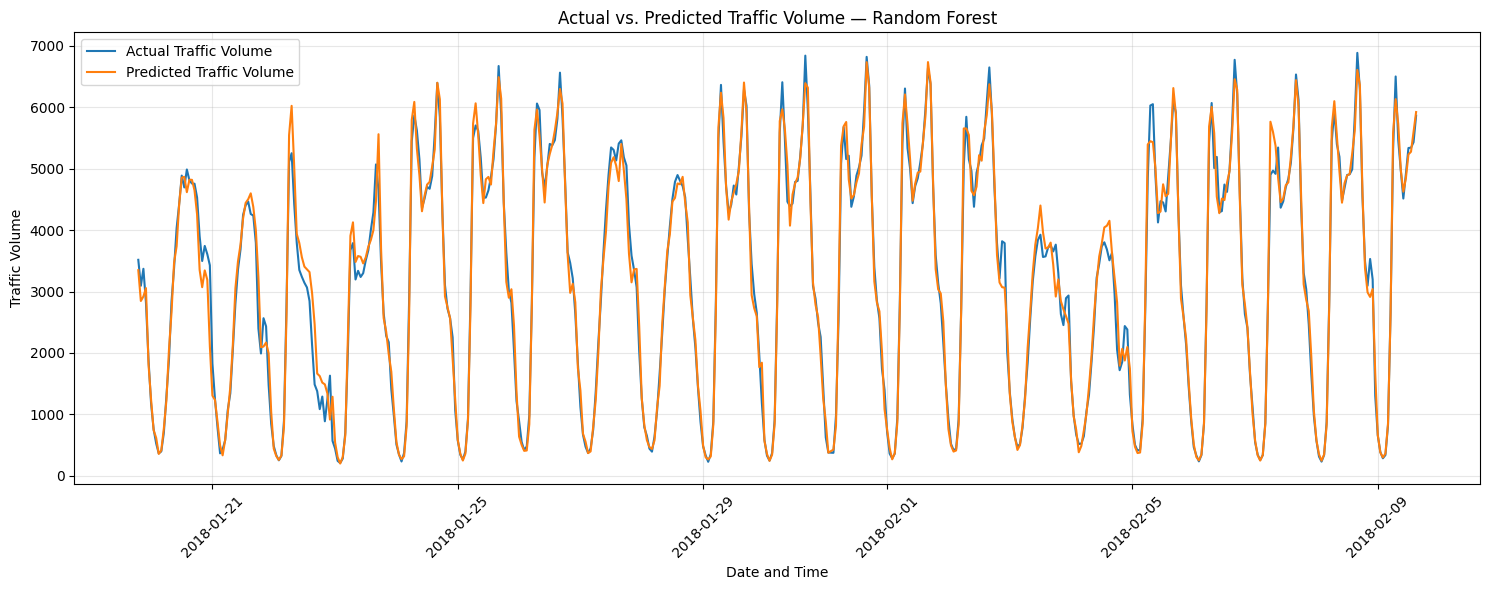

Graph saved to: /content/drive/MyDrive/Time_Series_Task1/actual_vs_predicted_traffic.png


In [25]:

# Actual vs. Predicted Traffic Volume — Random Forest

import matplotlib.pyplot as plt
from pathlib import Path

# Combine actual and predicted values with timestamps
plot_df = pd.DataFrame({
    "date_time": test_df["date_time"].values,
    "Actual Traffic Volume": y_test.values,
    "Predicted Traffic Volume": rf_test_pred
})

# Plot the first 500 test observations for readability
plot_sample = plot_df.iloc[:500]

plt.figure(figsize=(15, 6))
plt.plot(
    plot_sample["date_time"],
    plot_sample["Actual Traffic Volume"],
    label="Actual Traffic Volume",
    linewidth=1.5
)
plt.plot(
    plot_sample["date_time"],
    plot_sample["Predicted Traffic Volume"],
    label="Predicted Traffic Volume",
    linewidth=1.5
)

plt.title("Actual vs. Predicted Traffic Volume — Random Forest")
plt.xlabel("Date and Time")
plt.ylabel("Traffic Volume")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Save the graph to Google Drive
plot_path = Path(
    "/content/drive/MyDrive/Time_Series_Task1/"
    "actual_vs_predicted_traffic.png"
)
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Graph saved to: {plot_path}")


### Actual vs. Predicted Traffic Volume

The Random Forest predictions closely follow the actual traffic volume across the selected test observations, capturing recurring traffic patterns and daily fluctuations. Although some differences occur at individual points, the model demonstrates strong predictive performance, consistent with its test \(R^2\) of 0.9857 and MAE of approximately 150 vehicles.

## 6. Results and Conclusion

Six exploratory analyses examined traffic volume by hour, weekday versus weekend, day of the week, month, a 24-observation moving average, and the relationship between consecutive observations.

The analysis found that traffic volume was highest around 16:00 and lowest around 03:00. Weekday traffic averaged 3,557.44, compared with 2,623.93 on weekends. Friday had the highest daily average (3,674.78), while Sunday had the lowest (2,426.25). August had the highest monthly average (3,430.32), and December had the lowest (3,040.19). The correlation between consecutive observations was 0.8961, indicating a strong positive relationship.

Two forecasting approaches were compared. Linear Regression achieved a test MAE of 487.17, RMSE of 676.41, and R² of 0.8832. The tuned Random Forest model (200 trees, maximum depth 20) achieved a test MAE of 149.60, RMSE of 236.63, and R² of 0.9857. Random Forest therefore performed better on all three evaluation metrics.

The results suggest that traffic patterns and recent observations provide useful forecasting information, and that Random Forest captures these patterns more effectively than the linear baseline. However, the dataset contains gaps in its timestamps, so lag features represent previous available observations rather than always representing exact hourly intervals. This limitation should be considered when interpreting the forecasting results.